 Датасет создан: 1224 строк, 11 столбцов
----------------------------------------
 Дубликатов строк: 21
 Количество > 100 (выбросы): 3
 Цена <= 0 (ошибка): 2
----------------------------------------


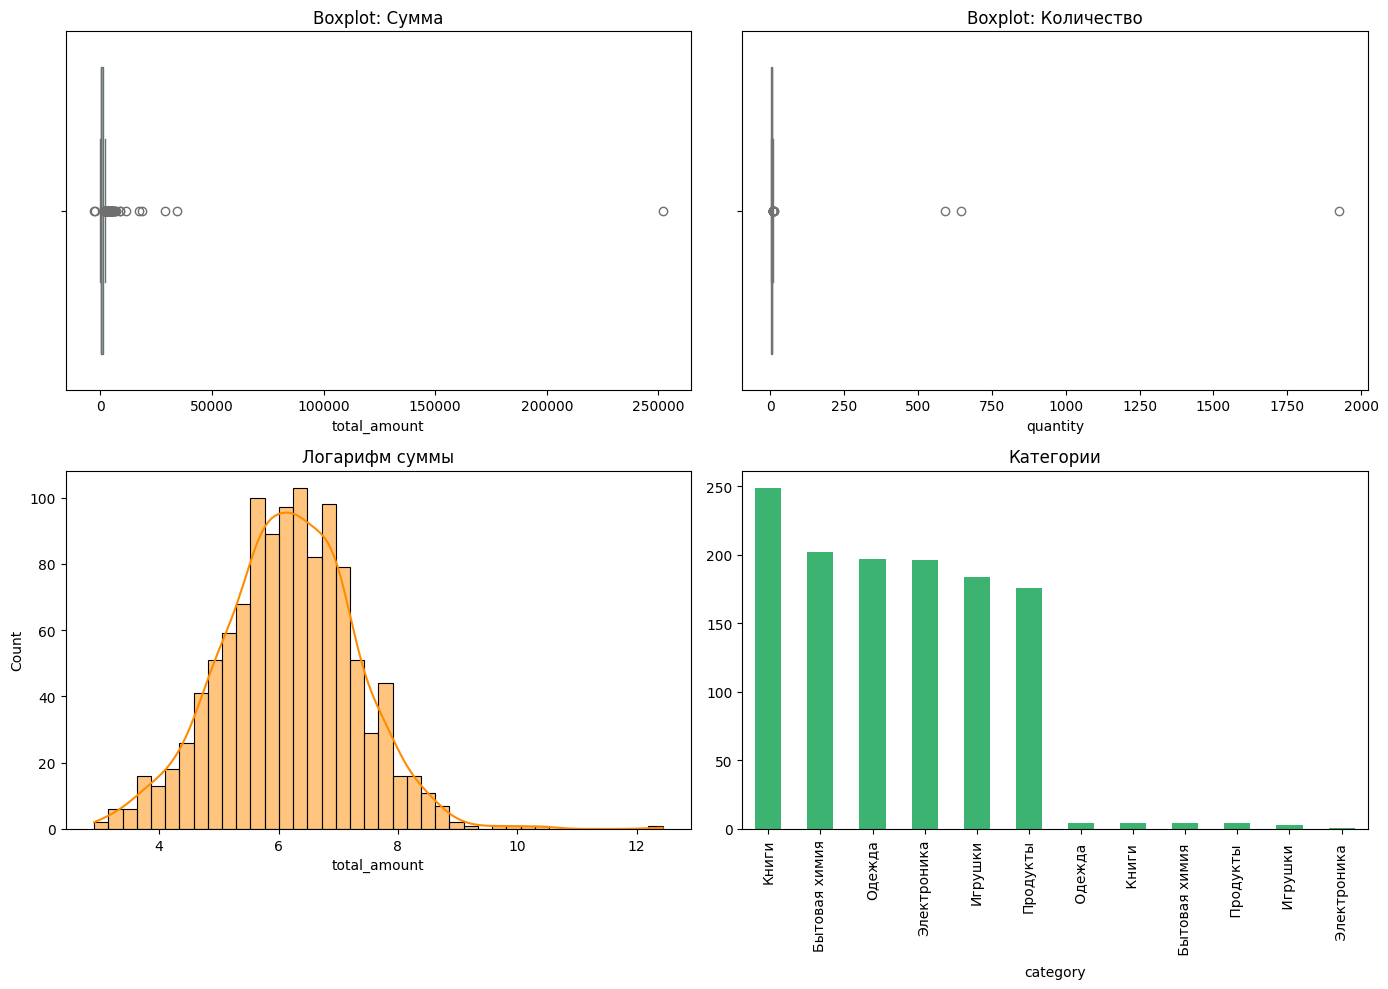

In [3]:
# 1. ИМПОРТЫ
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 2. ГЕНЕРАЦИЯ ДАННЫХ
n = 1200
regions = ['Москва', 'СПб', 'Казань', 'Новосибирск', 'Екатеринбург', 'Краснодар']
categories = ['Электроника', 'Одежда', 'Продукты', 'Книги', 'Бытовая химия', 'Игрушки']
delivery = ['Курьер', 'Почта', 'Самовывоз', 'Пункт выдачи']

df = pd.DataFrame({
    'order_id': [f'ORD{10000+i}' for i in range(n)],
    'order_date': pd.date_range('2023-01-01', periods=n, freq='7h') + pd.to_timedelta(np.random.randint(0, 300, n), unit='m'),
    'region': np.random.choice(regions, n, p=[0.3, 0.2, 0.15, 0.1, 0.15, 0.1]),
    'category': np.random.choice(categories, n),
    'delivery_type': np.random.choice(delivery, n, p=[0.4, 0.2, 0.25, 0.15]),
    'quantity': np.random.poisson(3, n) + 1,
    'unit_price': np.round(np.random.lognormal(5, 1, n), 2),
    'discount': np.random.choice([0, 0.05, 0.1, 0.15, 0.2, 0.3], n, p=[0.4, 0.15, 0.2, 0.1, 0.1, 0.05]),
    'customer_rating': np.random.choice([1, 2, 3, 4, 5, np.nan], n, p=[0.05, 0.1, 0.2, 0.3, 0.3, 0.05]),
    'is_returned': np.random.choice([0, 1], n, p=[0.92, 0.08])
})

df['total_amount'] = df['quantity'] * df['unit_price'] * (1 - df['discount'])

# --- Портим данные (пропуски, дубликаты, выбросы) ---
idx = np.random.choice(n, int(n*0.07), replace=False)
df.loc[idx, 'unit_price'] = np.nan
idx = np.random.choice(n, int(n*0.05), replace=False)
df.loc[idx, 'discount'] = np.nan
idx = np.random.choice(n, int(n*0.02), replace=False)
df = pd.concat([df, df.iloc[idx]], ignore_index=True)
out = np.random.choice(len(df), 5, replace=False)
df.loc[out[:3], 'quantity'] = np.random.randint(500, 2000, 3)
df.loc[out[3:], 'unit_price'] = -np.round(np.random.uniform(100, 1000, 2), 2)
df.loc[df.sample(30, random_state=1).index, 'region'] = df['region'].str.lower()
df.loc[df.sample(20, random_state=2).index, 'category'] = ' ' + df['category'] + ' '
df['total_amount'] = df['quantity'] * df['unit_price'] * (1 - df['discount'].fillna(0))

# Сохраняем в файл (Коллаб скачает его на комп)
df.to_csv('dataset.csv', index=False)

print(f" Датасет создан: {df.shape[0]} строк, {df.shape[1]} столбцов")
print("-" * 40)

# 3. АУДИТ
print(" Дубликатов строк:", df.duplicated().sum())
print(" Количество > 100 (выбросы):", (df['quantity'] > 100).sum())
print(" Цена <= 0 (ошибка):", (df['unit_price'] <= 0).sum())
print("-" * 40)

# 4. ГРАФИКИ
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.boxplot(x=df['total_amount'], ax=axes[0, 0], color='skyblue').set_title('Boxplot: Сумма')
sns.boxplot(x=df['quantity'], ax=axes[0, 1], color='lightgreen').set_title('Boxplot: Количество')
sns.histplot(np.log1p(df['total_amount'].dropna()), bins=40, kde=True, ax=axes[1, 0], color='darkorange').set_title('Логарифм суммы')
df['category'].value_counts().plot(kind='bar', ax=axes[1, 1], color='mediumseagreen').set_title('Категории')
plt.tight_layout()
plt.show()

# Лабораторная работа №1: Первичное исследование и оценка качества данных

## 1. Постановка задачи (Business Understanding)

**Что это за данные:**
Датасет содержит информацию о заказах интернет-магазина за 2023 год. В нём 11 признаков: ID заказа, дата, регион клиента, категория товара, способ доставки, количество, цена, скидка, итоговая сумма, оценка клиента и флаг возврата.

**Кто заказчик:**
Маркетинговый отдел и отдел логистики интернет-магазина. Им нужно понимать, какие регионы и категории приносят больше выручки, где теряются деньги из-за скидок и как доставка влияет на оценку клиента.

**Возможные задачи ИАД:**
1. **Сегментация заказов** — кластеризация по сумме, скидке и количеству товаров (выделение оптовиков, экономных и т.д.).
2. **Поиск аномалий** — выявление подозрительно больших сумм, отрицательных цен или ошибок ввода.
3. **Описательная аналитика** — профилирование регионов и категорий по средней выручке.

## 2. Паспорт датасета (Data Understanding)

- **Размер:** 1224 строки, 11 столбцов.
- **Типы данных:** дата (`order_date`), числовые (`quantity`, `unit_price`, `discount`, `total_amount`, `customer_rating`), текстовые/категориальные (`region`, `category`, `delivery_type`, `order_id`), бинарный флаг (`is_returned`).
- **Пропуски:** есть в `unit_price` (~7%), `total_amount` (~7%), `discount` (~5%), `customer_rating` (~5%).

## 4. Мини-EDA (Разведочный анализ)

**Вывод по графикам:**
- **Boxplot:** видны единичные аномально большие заказы (выбросы до 400 000 руб. и 1500 единиц товара).
- **Логарифм суммы:** исходное распределение сильно скошено, но логарифмирование делает его похожим на нормальное.
- **Категории:** у некоторых категорий есть дубликаты из-за лишних пробелов (например, "Бытовая химия" и " Бытовая химия "), что подтверждает проблему «грязных» данных.

## 5. Типы признаков и шкалы измерения (Задание 1)

| Признак | Тип шкалы | Среднее | Медиана | Мода |
|---|---|---|---|---|
| order_id | Номинальная | Нет | Нет | Да |
| order_date | Интервальная | Нет | Да | Нет |
| region | Номинальная | Нет | Нет | Да |
| category | Номинальная | Нет | Нет | Да |
| delivery_type | Номинальная | Нет | Нет | Да |
| quantity | Отношений | Да | Да | Да |
| unit_price | Отношений | Да | Да | Редко |
| discount | Отношений | Да | Да | Да |
| customer_rating | Порядковая | Некорректно | Да | Да |
| is_returned | Номинальная (бинарная) | Как доля | Нет | Да |
| total_amount | Отношений | Да | Да | Редко |

**Анализ двух признаков с разными шкалами:**

1. **region (номинальная шкала):** Вычислять среднее и медиану бессмысленно, так как это просто названия городов. Единственный корректный агрегат — мода (самый частый регион).
2. **total_amount (шкала отношений):** Среднее, медиана и мода математически корректны. Однако из-за сильных выбросов (тяжелого хвоста) среднее значение будет сильно завышено. Медиана в данном случае лучше отражает типичную сумму заказа.